# Model 2 - Logistic regression + lottery (the final model)

**What changed from Model 1** (`01_random_forest_lottery`):

| | Model 1 | Model 2 (this notebook) |
|---|---|---|
| Algorithm | Random forest (200 trees) | **Logistic regression** |
| Lottery | undersampling, ratio 0.45 | same - kept unchanged |
| Data preparation | same | same |
| Decision threshold | fixed 0.45 | **chosen from a recall target** using cross-validated training data |

**Why this change:** the relationships in the data are mostly monotonic and noisy (the strongest feature correlates with churn at only about 0.26). A flexible forest memorises noise; logistic regression gives each feature one weight, so it generalises better, ranks employees better, and is easy to explain.

**Why the threshold changed:** the lottery inflates predicted probabilities, so a fixed 0.45 is arbitrary. Instead we pick the cut-off that catches a chosen share of real leavers (`RECALL_TARGET`) - computed on training data only, so the test set is never used for tuning.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.metrics import (classification_report, confusion_matrix, balanced_accuracy_score,
                             roc_auc_score, average_precision_score, roc_curve)
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

## 1. Load the data and create the target

In [2]:
NAME = "employee_churn_ecommerce_retail_5000_10cols.csv"      # original data (12.3% churn). Swap in the augmented CSV to experiment.
candidates = [Path(NAME), Path("data") / NAME, Path("..") / "data" / NAME, Path("..") / NAME]
DATA_PATH = next((p for p in candidates if p.exists()), None)
assert DATA_PATH is not None, f"Could not find {NAME}. Put it next to this notebook or in a data/ folder."

df = pd.read_csv(DATA_PATH)
termination_col = "termination_date"
df["Churn"] = df[termination_col].notna().astype(int)         # a blank termination date = still employed

print(f"File: {DATA_PATH}")
print(f"Employees: {len(df)}")
print("\nChurn distribution:")
print(df["Churn"].value_counts().rename({0: "stayed", 1: "left"}))
print(f"Churn rate: {df['Churn'].mean():.1%}   |   'flag nobody' accuracy would be {1 - df['Churn'].mean():.1%}")

File: employee_churn_ecommerce_retail_5000_10cols.csv
Employees: 5000

Churn distribution:
Churn
stayed    4387
left       613
Name: count, dtype: int64
Churn rate: 12.3%   |   'flag nobody' accuracy would be 87.7%


## 2. Split before the lottery

In [3]:
# employee_id is just a label (5,000 unique values) and termination_date would give away the answer -> not used as inputs
X = df.drop(columns=["Churn", termination_col, "employee_id"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

P, N = int(y_test.sum()), int((y_test == 0).sum())
print(f"Training: {len(y_train)} employees ({y_train.sum()} leavers)")
print(f"Test:     {len(y_test)} employees = {P} leavers + {N} stayers (locked away until evaluation)")

Training: 4000 employees (490 leavers)
Test:     1000 employees = 123 leavers + 877 stayers (locked away until evaluation)


## 3. Prepare the inputs
Unchanged from Model 1.

In [4]:
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
categorical_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numeric inputs:    ", numeric_cols)
print("Categorical inputs:", categorical_cols)

numeric_pipeline = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="median")),            # blank number -> median of the training data
    ("scaler", StandardScaler())])                            # put all numbers on a common scale
categorical_pipeline = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),     # blank category -> most common value
    ("encoder", OneHotEncoder(handle_unknown="ignore"))])     # category -> yes/no columns

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)])

Numeric inputs:     ['age', 'years_at_company', 'monthly_salary', 'overtime_hours_per_month', 'job_satisfaction', 'performance_rating']
Categorical inputs: ['department', 'job_level']


## 4. The lottery (random undersampling)
Unchanged from Model 1.

In [5]:
lottery = RandomUnderSampler(sampling_strategy=0.45, random_state=42)

# What the lottery does to the training set (applied only inside the pipeline, only while training)
Z_demo = preprocessor.fit_transform(X_train)
_, y_demo = lottery.fit_resample(Z_demo, y_train)
print(f"Before the lottery: {int((y_train == 0).sum())} stayers vs {int(y_train.sum())} leavers")
print(f"After the lottery:  {int((y_demo == 0).sum())} stayers vs {int(y_demo.sum())} leavers (leavers = {y_demo.sum() / (y_demo == 0).sum():.0%} of stayers)")

Before the lottery: 3510 stayers vs 490 leavers
After the lottery:  1088 stayers vs 490 leavers (leavers = 45% of stayers)


## 5. Build the model

In [6]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("lottery", lottery),
    ("classifier", LogisticRegression(max_iter=1000))])

## 6. Choose the threshold from a recall target

1. Run 5-fold cross-validation **on the training data** so every training employee gets an honest score from a model that never saw them.
2. Take the scores of the real leavers and sort them.
3. The threshold is the score below which `(1 - RECALL_TARGET)` of the leavers fall - so about `RECALL_TARGET` of leavers score above it.

Change `RECALL_TARGET` to trade false alarms against missed leavers (0.5 = fewer false alarms, 0.7 = catch more leavers).

In [7]:
RECALL_TARGET = 0.60       # <- the one setting to tune

oof = cross_val_predict(model, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=42),
                        method="predict_proba")[:, 1]
pos = np.sort(oof[y_train.values == 1])
threshold = pos[int(np.floor((1 - RECALL_TARGET) * len(pos)))]
print(f"Recall target {RECALL_TARGET:.0%} -> decision threshold {threshold:.3f} (chosen from training data only)")

model.fit(X_train, y_train)

Recall target 60% -> decision threshold 0.353 (chosen from training data only)


,steps,"[('preprocessor', ...), ('lottery', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for f

## 7. Evaluate on the untouched test set

In [8]:
p = model.predict_proba(X_test)[:, 1]                         # churn probability for each test employee
predictions = (p >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()

print(f"Decision threshold: {threshold:.3f}\n")
print("========== CONFUSION MATRIX ==========")
print("                 Predicted")
print("                 Not Churn   Churn")
print(f"Actual Not Churn    {tn:5d}     {fp:5d}")
print(f"Actual Churn       {fn:5d}     {tp:5d}")
print("\n========== CLASSIFICATION RESULTS ==========")
print(f"True Positives (TP):  {tp:4d}   leavers correctly flagged              ({tp/(tp+fn):.1%} of all leavers)")
print(f"True Negatives (TN):  {tn:4d}   stayers correctly left alone           ({tn/(tn+fp):.1%} of all stayers)")
print(f"False Positives (FP): {fp:4d}   stayers wrongly flagged (false alarms) ({fp/(fp+tn):.1%} of all stayers)")
print(f"False Negatives (FN): {fn:4d}   leavers we missed                      ({fn/(fn+tp):.1%} of all leavers)")
print("\n========== PERFORMANCE METRICS ==========")
print(classification_report(y_test, predictions, labels=[0, 1], target_names=["Not churned", "Churned"], zero_division=0))
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, predictions):.3f}   (0.5 = guessing)")
print(f"ROC AUC:           {roc_auc_score(y_test, p):.3f}   (0.5 = guessing)")
print(f"PR-AUC:            {average_precision_score(y_test, p):.3f}   (guessing = {y_test.mean():.3f})")
print(f"Precision: {tp/max(tp+fp,1):.1%} of flags are real leavers (random flagging would be {y_test.mean():.1%})")

Decision threshold: 0.353

========== CONFUSION MATRIX ==========
                 Predicted
                 Not Churn   Churn
Actual Not Churn      626       251
Actual Churn          46        77

========== CLASSIFICATION RESULTS ==========
True Positives (TP):    77   leavers correctly flagged              (62.6% of all leavers)
True Negatives (TN):   626   stayers correctly left alone           (71.4% of all stayers)
False Positives (FP):  251   stayers wrongly flagged (false alarms) (28.6% of all stayers)
False Negatives (FN):   46   leavers we missed                      (37.4% of all leavers)

========== PERFORMANCE METRICS ==========
              precision    recall  f1-score   support

 Not churned       0.93      0.71      0.81       877
     Churned       0.23      0.63      0.34       123

    accuracy                           0.70      1000
   macro avg       0.58      0.67      0.57      1000
weighted avg       0.85      0.70      0.75      1000

Balanced accuracy: 0.

## 8. Confusion matrix picture

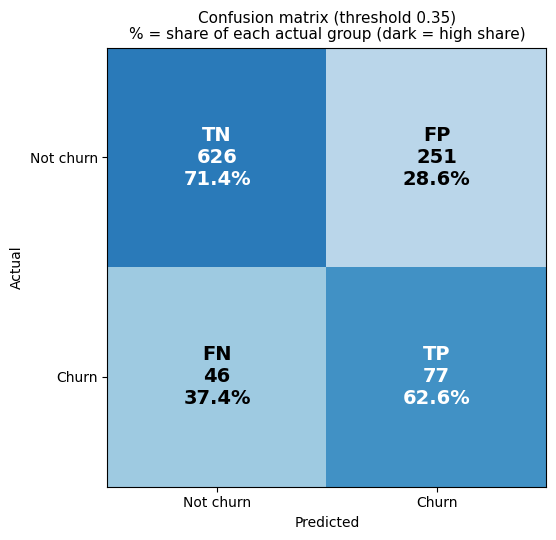

In [9]:
cm = np.array([[tn, fp], [fn, tp]])
row_pct = cm / cm.sum(axis=1, keepdims=True)
cell_names = [["TN", "FP"], ["FN", "TP"]]
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(row_pct, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cell_names[i][j]}\n{cm[i, j]}\n{row_pct[i, j]:.1%}", ha="center", va="center",
                color="white" if row_pct[i, j] > 0.5 else "black", fontsize=14, fontweight="bold")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Not churn", "Churn"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Not churn", "Churn"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"Confusion matrix (threshold {threshold:.2f})\n% = share of each actual group (dark = high share)", fontsize=11)
plt.tight_layout(); plt.show()

## 9. ROC curve

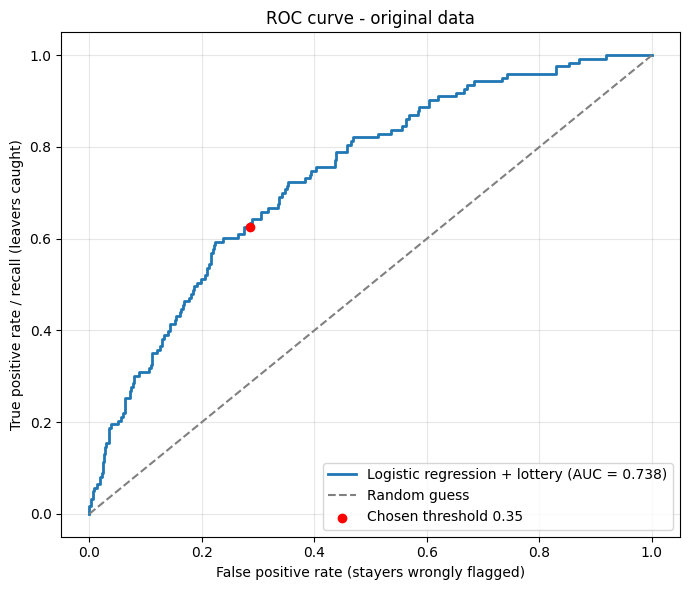

In [10]:
fpr_curve, tpr_curve, _ = roc_curve(y_test, p)
plt.figure(figsize=(7, 6))
plt.plot(fpr_curve, tpr_curve, linewidth=2, label=f"Logistic regression + lottery (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
plt.scatter([fp / (fp + tn)], [tp / (tp + fn)], color="red", zorder=5, label=f"Chosen threshold {threshold:.2f}")
plt.xlabel("False positive rate (stayers wrongly flagged)")
plt.ylabel("True positive rate / recall (leavers caught)")
plt.title("ROC curve - original data")
plt.legend(loc="lower right"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 10. How the threshold changes with the recall target
Each row re-computes the threshold from training data for a different target, then scores the test set. Pick the row that fits how costly a false alarm is compared with a missed leaver.

In [11]:
rows = []
for target in (0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9):
    thr = pos[int(np.floor((1 - target) * len(pos)))]
    pr = (p >= thr).astype(int)
    t_n, f_p, f_n, t_p = confusion_matrix(y_test, pr, labels=[0, 1]).ravel()
    rows.append({"recall target": f"{target:.0%}", "threshold": round(float(thr), 3), "flagged": t_p + f_p,
                 "leavers caught": t_p, "false alarms": f_p, "missed": f_n,
                 "actual recall": f"{t_p/(t_p+f_n):.1%}", "precision": f"{t_p/max(t_p+f_p,1):.1%}",
                 "balanced acc.": round(balanced_accuracy_score(y_test, pr), 3)})
pd.DataFrame(rows)

,recall target,threshold,flagged,leavers caught,false alarms,missed,actual recall,precision,balanced acc.
0,30%,0.552,113,37,76,86,30.1%,32.7%,0.607
1,40%,0.482,165,48,117,75,39.0%,29.1%,0.628
2,50%,0.430,227,61,166,62,49.6%,26.9%,0.653
3,60%,0.353,328,77,251,46,62.6%,23.5%,0.670
4,70%,0.293,423,89,334,34,72.4%,21.0%,0.671
5,80%,0.226,544,101,443,22,82.1%,18.6%,0.658
6,90%,0.156,686,113,573,10,91.9%,16.5%,0.633


## 11. Risk tiers
Ranking employees and grouping them is more useful (and more honest) than one hard yes/no, because it is robust to the lottery inflating the probabilities.

In [12]:
t = pd.DataFrame({"p": p, "y": y_test.values})
t["rank_pct"] = t.p.rank(pct=True, ascending=False)
t["tier"] = pd.cut(t.rank_pct, [0, 0.10, 0.30, 1.0], labels=["HIGH (top 10%)", "MEDIUM (next 20%)", "LOW (bottom 70%)"])
tiers = t.groupby("tier", observed=True).y.agg(employees="count", leavers="sum", churn_rate="mean")
tiers["share_of_all_leavers"] = tiers.leavers / P
tiers.assign(churn_rate=(tiers.churn_rate * 100).round(1).astype(str) + "%",
             share_of_all_leavers=(tiers.share_of_all_leavers * 100).round(1).astype(str) + "%")

,employees,leavers,churn_rate,share_of_all_leavers
tier,,,,
HIGH (top 10%),100,34,34.0%,27.6%
MEDIUM (next 20%),200,40,20.0%,32.5%
LOW (bottom 70%),700,49,7.0%,39.8%


## 12. Explainability - what the model learned
Each input has one weight (inputs are scaled, so weights are per one standard deviation). Positive = pushes toward leaving, negative = toward staying.

**Read with care:** salary and job level overlap heavily (correlation about 0.86), so their weights partly offset each other. For example, `job_level_Manager` shows a positive weight even though managers rarely leave (2.2% churn) - the negative `monthly_salary` weight carries that effect. A weight means "holding the other inputs fixed", so trust the overall pattern (low satisfaction, high overtime, low pay, junior roles) more than any single category.

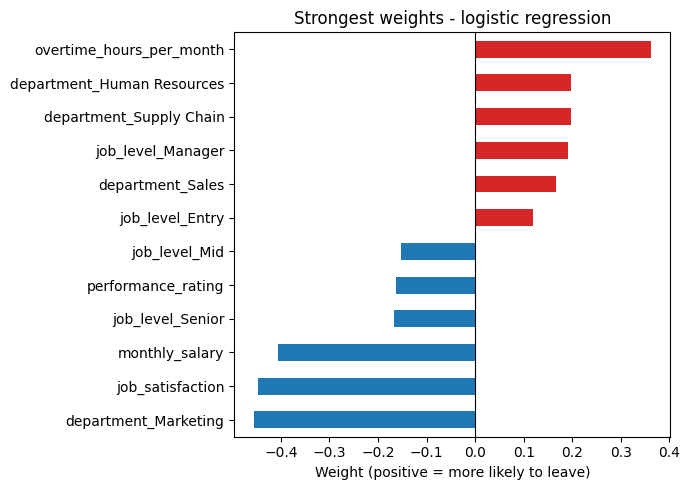

In [13]:
names = [n.split("__", 1)[-1] for n in model.named_steps["preprocessor"].get_feature_names_out()]
coef = pd.Series(model.named_steps["classifier"].coef_[0], index=names).sort_values()
top = pd.concat([coef.head(6), coef.tail(6)])
ax = top.plot.barh(figsize=(7, 5), color=["#d62728" if v > 0 else "#1f77b4" for v in top])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Weight (positive = more likely to leave)"); ax.set_title("Strongest weights - logistic regression")
plt.tight_layout(); plt.show()

## 13. Diagnostics and stability

In [14]:
# Two diagnostics that explain the weaknesses and motivate the next step
auc_train = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
auc_test = roc_auc_score(y_test, p)
print(f"1) Overfitting check  - AUC on the data it trained on: {auc_train:.3f}  vs  AUC on unseen test data: {auc_test:.3f}")
print(f"   (a big gap means the model memorised noise)")
print(f"2) Probability check  - average predicted churn probability: {p.mean():.1%}  vs  real churn rate: {y_test.mean():.1%}")
print(f"   (the lottery removes stayers during training, so the model over-predicts churn; the threshold is not a real probability)")

1) Overfitting check  - AUC on the data it trained on: 0.759  vs  AUC on unseen test data: 0.738
   (a big gap means the model memorised noise)
2) Probability check  - average predicted churn probability: 28.7%  vs  real churn rate: 12.3%
   (the lottery removes stayers during training, so the model over-predicts churn; the threshold is not a real probability)


In [15]:
# Stability check: repeat the whole pipeline on 5 different splits of ALL the data
aucs, aps = [], []
for tr, te in StratifiedKFold(5, shuffle=True, random_state=7).split(X, y):
    m = clone(model).fit(X.iloc[tr], y.iloc[tr])
    pp = m.predict_proba(X.iloc[te])[:, 1]
    aucs.append(roc_auc_score(y.iloc[te], pp)); aps.append(average_precision_score(y.iloc[te], pp))
print(f"5-fold cross-validation:  ROC AUC {np.mean(aucs):.3f} +/- {np.std(aucs):.3f}   |   PR-AUC {np.mean(aps):.3f} +/- {np.std(aps):.3f}")

5-fold cross-validation:  ROC AUC 0.747 +/- 0.016   |   PR-AUC 0.329 +/- 0.023


## 14. Summary - Model 1 vs Model 2

Results on the **original data** (12.3% churn, 123 leavers + 877 stayers in the test set):

| | Model 1: random forest, fixed 0.45 | Model 2: logistic, 60% recall target |
|---|---|---|
| Leavers caught (TP) | 54 (43.9%) | 77 (62.6%) |
| False alarms (FP) | 163 | 251 |
| Precision | 24.9% | 23.5% |
| Balanced accuracy | 0.627 | **0.670** |
| ROC AUC | 0.699 | **0.738** |
| PR-AUC | 0.249 | **0.290** |

The two rows catch different numbers of leavers, so false alarms alone can't be compared. **At the same recall**, Model 2 raises about 18% fewer false alarms on average (for example 209 instead of 289 at 60% recall), and its ranking quality (AUC) is clearly higher in both the test set and 5-fold cross-validation.

**Limits (honest summary):** precision stays low (about a quarter of flags are real leavers) because the signal in the columns is moderate. About ten different model types all reached an AUC of about 0.75, so the ceiling comes from the information in the data, not the algorithm. New features (manager, promotions, time since last raise) are the only real way to improve further.

**Next notebooks:** `03_lottery_ticket_hypothesis` (a separate neural-network experiment) and `04_compare_models_confusion_matrices` (side-by-side comparison).